In [48]:
from pathlib import Path
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)

# Locate project root
current_path = Path.cwd()

project_root = next(
    (
        path
        for path in [current_path, *current_path.parents]
        if (path / "src" / "config.py").exists()
    ),
    None,
)

if project_root is None:
    raise FileNotFoundError(
        "Could not locate the project root containing src/config.py."
    )

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

print(f"Project root: {project_root}")

Project root: /Users/soham/MyDocs/Projects/Cricket Analysis/Hackathon - DPL 2026/CodeFiles/Hackathon_DPL2026


In [49]:
from src.data_loader import load_raw_data
from src.features.metric_definitions import add_metric_features
from src.features.match_level import (
    build_match_summary,
    build_team_match,
)
from src.features.player_level import (
    build_player_season_batting,
    build_player_season_bowling,
    build_player_season_phase_batting,
    build_player_season_phase_bowling,
)

# Load raw data and derive validated metric features
df = load_raw_data()
df_features = add_metric_features(df)

# Build analytical tables
match_summary = build_match_summary(df_features)
team_match = build_team_match(df_features)

player_season_batting = build_player_season_batting(df_features)
player_season_bowling = build_player_season_bowling(df_features)

player_season_phase_batting = build_player_season_phase_batting(
    df_features
)
player_season_phase_bowling = build_player_season_phase_bowling(
    df_features
)

print("Data loaded and analytical tables built successfully.")

print(f"\nDelivery records: {len(df_features):,}")
print(f"Matches: {len(match_summary):,}")
print(f"Team-match records: {len(team_match):,}")
print(f"Player-season batting records: {len(player_season_batting):,}")
print(f"Player-season bowling records: {len(player_season_bowling):,}")
print(f"Phase-wise batting records: {len(player_season_phase_batting):,}")
print(f"Phase-wise bowling records: {len(player_season_phase_bowling):,}")

Data loaded and analytical tables built successfully.

Delivery records: 34,967
Matches: 145
Team-match records: 290
Player-season batting records: 347
Player-season bowling records: 273
Phase-wise batting records: 733
Phase-wise bowling records: 672


In [50]:
# Consistent visual style for the final presentation

SEASON_COLORS = {
    2023: "#4472C4",
    2024: "#ED7D31",
}

plt.rcParams.update({
    "figure.figsize": (10, 6),
    "figure.dpi": 120,
    "axes.titlesize": 14,
    "axes.labelsize": 11,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": False,
})

print("Visualisation style configured.")
print("2023: Blue | 2024: Orange")

Visualisation style configured.
2023: Blue | 2024: Orange


## 1. KKR Season Performance: 2023 vs 2024

This section compares KKR's recorded match outcomes across the two seasons, using the validated team-match aggregation.

**Coverage caveat:** The dataset contains 14 represented KKR matches per season. The 2023 sample comprises 14 league matches, while the 2024 sample comprises 12 league matches and two playoffs. KKR's final two league matches in 2024 are absent from the dataset.

Consequently, this is a comparison of the matches represented in the dataset, not a complete, like-for-like comparison of the two league seasons.

In [51]:
# Prepare KKR season-level match outcomes

kkr_team_matches = team_match.loc[
    team_match["team"].eq("Kolkata Knight Riders")
].copy()

kkr_season_summary = (
    kkr_team_matches
    .groupby("year")
    .agg(
        matches_represented=("p_match", "nunique"),
        wins=("team_result", lambda s: s.eq("win").sum()),
        losses=("team_result", lambda s: s.eq("loss").sum()),
        unclassified=(
            "team_result",
            lambda s: s.eq("Unclassified").sum()
        ),
    )
    .reset_index()
)

kkr_season_summary["classified_matches"] = (
    kkr_season_summary["wins"] + kkr_season_summary["losses"]
)

kkr_season_summary["win_pct"] = (
    100
    * kkr_season_summary["wins"]
    / kkr_season_summary["classified_matches"]
)

display(kkr_season_summary.round(2))

,year,matches_represented,wins,losses,unclassified,classified_matches,win_pct
0,2023,14,6,8,0,14,42.86
1,2024,14,11,3,0,14,78.57


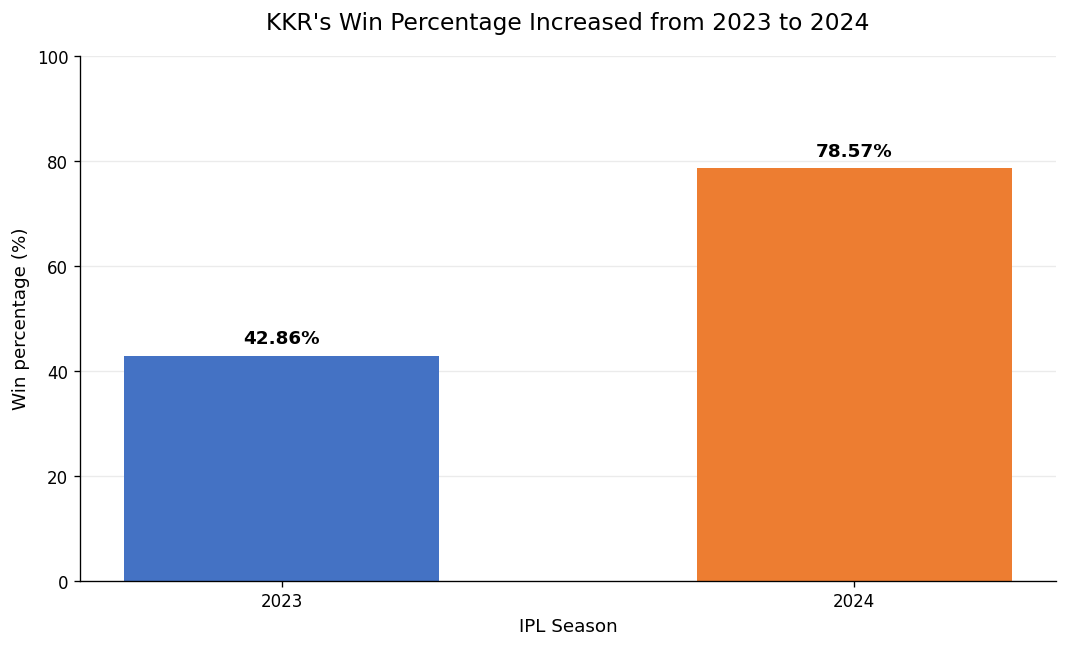

In [52]:
# Plot KKR's win percentage by season

fig, ax = plt.subplots(figsize=(9, 5.5))

bars = ax.bar(
    kkr_season_summary["year"].astype(str),
    kkr_season_summary["win_pct"],
    color=[
        SEASON_COLORS[year]
        for year in kkr_season_summary["year"]
    ],
    width=0.55,
)

ax.set_title(
    "KKR's Win Percentage Increased from 2023 to 2024",
    pad=16,
)
ax.set_xlabel("IPL Season")
ax.set_ylabel("Win percentage (%)")
ax.set_ylim(0, 100)

ax.bar_label(
    bars,
    labels=[
        f'{value:.2f}%'
        for value in kkr_season_summary["win_pct"]
    ],
    padding=5,
    fontsize=11,
    fontweight="bold",
)

ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

## 2. Batting Performance Across Match Phases

This section compares KKR's scoring rate across the Powerplay, Middle Overs, and Death Overs in 2023 and 2024.

Scoring rate is calculated as runs scored off the bat per six balls faced. This makes the comparison intuitive while retaining the distinction between balls faced and legal deliveries.

**Coverage caveat:** The 2024 Death Overs figures cover 12 represented matches, compared with 14 in 2023. Two 2024 chases ended before the 16th over, so no Death Overs batting data was recorded for those matches.

In [53]:
# Aggregate KKR batting performance by season and match phase

kkr_batting_deliveries = df_features.loc[
    df_features["team_bat"].eq("Kolkata Knight Riders")
].copy()

kkr_batting_phase = (
    kkr_batting_deliveries
    .groupby(["year", "match_phase"], observed=True)
    .agg(
        runs=("batruns", "sum"),
        balls_faced=("ballfaced", "sum"),
        dot_balls=("batting_dot", "sum"),
        boundary_balls=("boundary_ball", "sum"),
        matches=("p_match", "nunique"),
    )
    .reset_index()
)

kkr_batting_phase["runs_per_over"] = (
    6 * kkr_batting_phase["runs"]
    / kkr_batting_phase["balls_faced"]
)

phase_order = ["Powerplay", "Middle", "Death"]

kkr_batting_phase["match_phase"] = pd.Categorical(
    kkr_batting_phase["match_phase"],
    categories=phase_order,
    ordered=True,
)

kkr_batting_phase = kkr_batting_phase.sort_values(
    ["match_phase", "year"]
)

display(kkr_batting_phase.round(2))

,year,match_phase,runs,balls_faced,dot_balls,boundary_balls,matches,runs_per_over
2,2023,Powerplay,651,507,264,109,14,7.70
5,2024,Powerplay,849,507,231,153,14,10.05
1,2023,Middle,1065,760,233,130,14,8.41
4,2024,Middle,1114,725,224,149,14,9.22
0,2023,Death,622,390,146,88,14,9.57
3,2024,Death,518,275,83,77,12,11.30


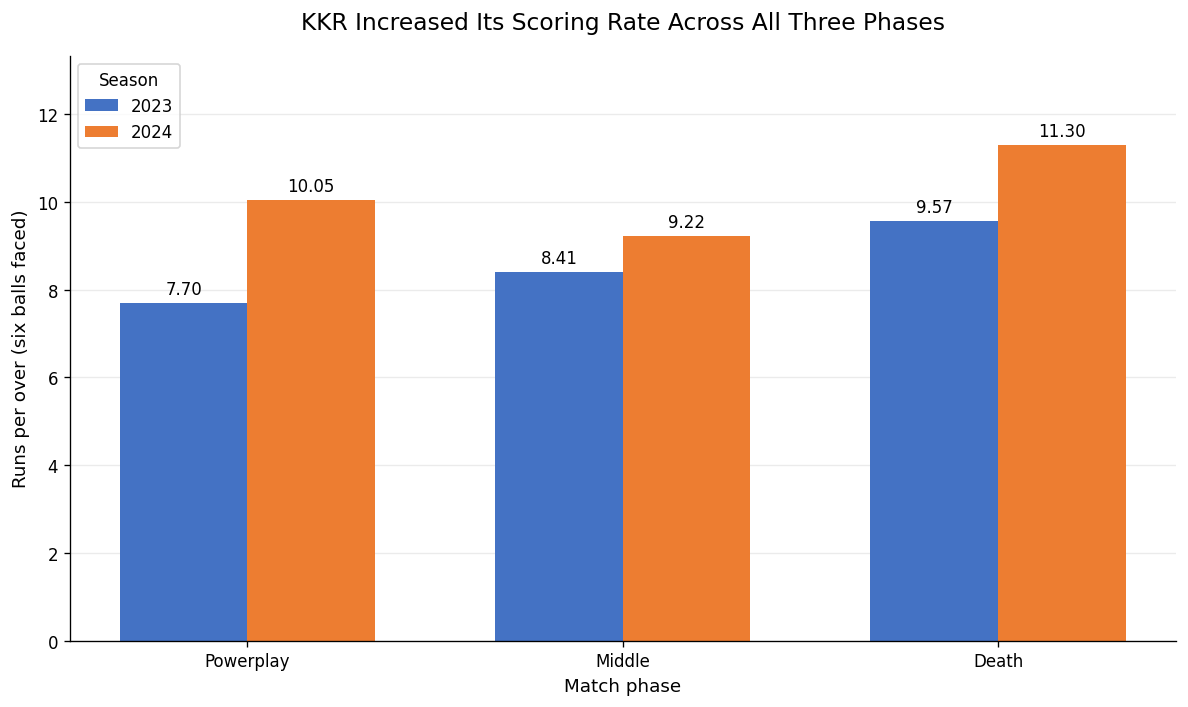

In [54]:
# Grouped bar chart: KKR batting scoring rate by phase

plot_data = kkr_batting_phase.pivot(
    index="match_phase",
    columns="year",
    values="runs_per_over",
).reindex(phase_order)

x = np.arange(len(plot_data.index))
width = 0.34

fig, ax = plt.subplots(figsize=(10, 6))

bars_2023 = ax.bar(
    x - width / 2,
    plot_data[2023],
    width,
    label="2023",
    color=SEASON_COLORS[2023],
)

bars_2024 = ax.bar(
    x + width / 2,
    plot_data[2024],
    width,
    label="2024",
    color=SEASON_COLORS[2024],
)

ax.set_title(
    "KKR Increased Its Scoring Rate Across All Three Phases",
    pad=16,
)
ax.set_xlabel("Match phase")
ax.set_ylabel("Runs per over (six balls faced)")
ax.set_xticks(x)
ax.set_xticklabels(plot_data.index)
ax.set_ylim(0, max(plot_data.max()) * 1.18)

ax.bar_label(bars_2023, fmt="%.2f", padding=3)
ax.bar_label(bars_2024, fmt="%.2f", padding=3)

ax.legend(title="Season")
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

## 3. Bowling Performance Across Match Phases

This section compares KKR's bowling performance in 2023 and 2024 across the Powerplay, Middle Overs, and Death Overs.

We examine:
- **Economy rate:** runs conceded per six legal balls.
- **Dot-ball percentage:** percentage of legal deliveries on which no runs were scored.
- **Wickets per 20 overs:** bowler-credited wickets normalised to a common workload.

Lower economy and higher dot-ball and wicket rates generally indicate stronger bowling outcomes. However, these metrics must be interpreted together with bowling roles, workload, opposition, and match context.

The analysis uses the source dataset's bowling-run values. Previously identified inconsistencies in `bowlruns` remain a data-quality limitation.

In [55]:
# Aggregate KKR bowling performance by season and match phase

kkr_bowling_deliveries = df_features.loc[
    df_features["team_bowl"].eq("Kolkata Knight Riders")
].copy()

kkr_bowling_phase = (
    kkr_bowling_deliveries
    .groupby(["year", "match_phase"], observed=True)
    .agg(
        runs_conceded=("bowlruns", "sum"),
        legal_balls=("legal_delivery", "sum"),
        dot_balls=("bowling_dot", "sum"),
        wickets=("bowler_credited_wicket", "sum"),
        matches=("p_match", "nunique"),
    )
    .reset_index()
)

kkr_bowling_phase["overs_bowled"] = (
    kkr_bowling_phase["legal_balls"] / 6
)

kkr_bowling_phase["economy_rate"] = (
    kkr_bowling_phase["runs_conceded"]
    / kkr_bowling_phase["overs_bowled"]
)

kkr_bowling_phase["dot_ball_pct"] = (
    100
    * kkr_bowling_phase["dot_balls"]
    / kkr_bowling_phase["legal_balls"]
)

kkr_bowling_phase["wickets_per_20_overs"] = (
    20
    * kkr_bowling_phase["wickets"]
    / kkr_bowling_phase["overs_bowled"]
)

phase_order = ["Powerplay", "Middle", "Death"]

kkr_bowling_phase["match_phase"] = pd.Categorical(
    kkr_bowling_phase["match_phase"],
    categories=phase_order,
    ordered=True,
)

kkr_bowling_phase = kkr_bowling_phase.sort_values(
    ["match_phase", "year"]
)

display(kkr_bowling_phase.round(2))

,year,match_phase,runs_conceded,legal_balls,dot_balls,wickets,matches,overs_bowled,economy_rate,dot_ball_pct,wickets_per_20_overs
2,2023,Powerplay,806,504,198,20,14,84.00,9.60,39.29,4.76
5,2024,Powerplay,817,504,211,27,14,84.00,9.73,41.87,6.43
1,2023,Middle,1009,745,247,36,14,124.17,8.13,33.15,5.80
4,2024,Middle,1022,756,265,49,14,126.00,8.11,35.05,7.78
0,2023,Death,609,345,86,21,13,57.50,10.59,24.93,7.30
3,2024,Death,517,316,121,28,14,52.67,9.82,38.29,10.63


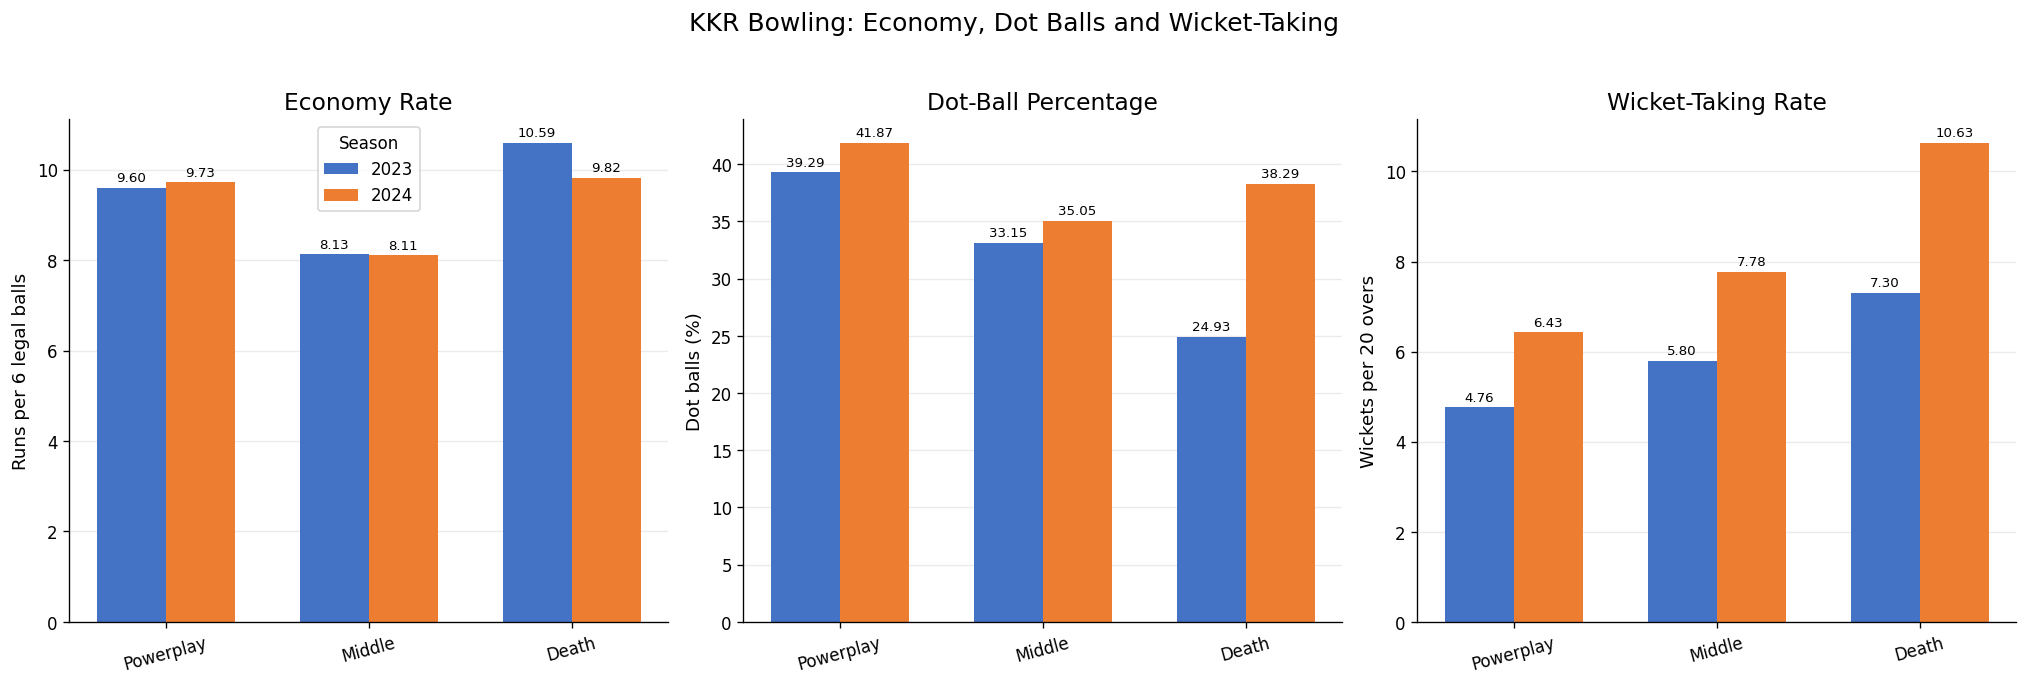

In [56]:
# Compare KKR bowling performance by match phase

metrics = [
    ("economy_rate", "Economy Rate", "Runs per 6 legal balls"),
    ("dot_ball_pct", "Dot-Ball Percentage", "Dot balls (%)"),
    ("wickets_per_20_overs", "Wicket-Taking Rate", "Wickets per 20 overs"),
]

fig, axes = plt.subplots(1, 3, figsize=(17, 5.5))

x = np.arange(len(phase_order))
width = 0.34

for ax, (metric, title, ylabel) in zip(axes, metrics):
    plot_data = (
        kkr_bowling_phase
        .pivot(index="match_phase", columns="year", values=metric)
        .reindex(phase_order)
    )

    bars_2023 = ax.bar(
        x - width / 2,
        plot_data[2023],
        width,
        label="2023",
        color=SEASON_COLORS[2023],
    )

    bars_2024 = ax.bar(
        x + width / 2,
        plot_data[2024],
        width,
        label="2024",
        color=SEASON_COLORS[2024],
    )

    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.set_xticks(x)
    ax.set_xticklabels(phase_order, rotation=15)
    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)

    ax.bar_label(bars_2023, fmt="%.2f", padding=2, fontsize=8)
    ax.bar_label(bars_2024, fmt="%.2f", padding=2, fontsize=8)

axes[0].legend(title="Season")

fig.suptitle(
    "KKR Bowling: Economy, Dot Balls and Wicket-Taking",
    fontsize=15,
    y=1.03,
)

plt.tight_layout()
plt.show()

## 4. Match-Level Indicators Associated with Winning

This section compares KKR's match-level batting and bowling performance in wins and losses.

The analysis uses complete KKR league matches only. It excludes the two 2024 playoffs and the incomplete match identified during the data audit.

Metrics include batting scoring rate, bowling economy, bowling dot-ball percentage, and bowler-credited wickets.

These are descriptive comparisons. Differences between wins and losses do not establish that a particular metric caused the result. Match conditions, opposition quality, targets, batting order, and other contextual factors can influence both performance and outcome.

In [57]:
# Build KKR match-level performance metrics

# Complete matches have two represented innings
complete_match_ids = set(
    match_summary.loc[
        match_summary["represented_innings"].eq(2),
        "p_match",
    ]
)

# KKR batting performance by match
kkr_batting_match = (
    df_features.loc[
        df_features["team_bat"].eq("Kolkata Knight Riders")
        & df_features["p_match"].isin(complete_match_ids)
    ]
    .groupby(["p_match", "year"], as_index=False)
    .agg(
        batting_runs=("batruns", "sum"),
        batting_balls=("ballfaced", "sum"),
        batting_dots=("batting_dot", "sum"),
        batting_wickets_lost=("out", "sum"),
    )
)

kkr_batting_match["batting_runs_per_over"] = (
    6 * kkr_batting_match["batting_runs"]
    / kkr_batting_match["batting_balls"]
)

# KKR bowling performance by match
kkr_bowling_match_summary = (
    df_features.loc[
        df_features["team_bowl"].eq("Kolkata Knight Riders")
        & df_features["p_match"].isin(complete_match_ids)
    ]
    .groupby(["p_match", "year"], as_index=False)
    .agg(
        bowling_runs_conceded=("bowlruns", "sum"),
        bowling_legal_balls=("legal_delivery", "sum"),
        bowling_dots=("bowling_dot", "sum"),
        bowling_wickets=("bowler_credited_wicket", "sum"),
    )
)

kkr_bowling_match_summary["bowling_economy"] = (
    6 * kkr_bowling_match_summary["bowling_runs_conceded"]
    / kkr_bowling_match_summary["bowling_legal_balls"]
)

kkr_bowling_match_summary["bowling_dot_pct"] = (
    100
    * kkr_bowling_match_summary["bowling_dots"]
    / kkr_bowling_match_summary["bowling_legal_balls"]
)

# Combine batting and bowling metrics
kkr_match_analysis = kkr_batting_match.merge(
    kkr_bowling_match_summary,
    on=["p_match", "year"],
    how="inner",
    validate="one_to_one",
)

# Attach match metadata
kkr_match_analysis = kkr_match_analysis.merge(
    match_summary[
        ["p_match", "winner", "represented_innings"]
    ],
    on="p_match",
    how="left",
    validate="one_to_one",
)

kkr_match_analysis["team_result"] = np.select(
    [
        kkr_match_analysis["winner"].eq("Kolkata Knight Riders"),
        kkr_match_analysis["winner"].notna()
        & kkr_match_analysis["winner"].ne("-")
        & kkr_match_analysis["winner"].ne("Kolkata Knight Riders"),
    ],
    ["Win", "Loss"],
    default="Unclassified",
)

print("KKR match-level table:", kkr_match_analysis.shape)
display(kkr_match_analysis.head())

KKR match-level table: (28, 16)


,p_match,year,batting_runs,batting_balls,batting_dots,batting_wickets_lost,batting_runs_per_over,bowling_runs_conceded,bowling_legal_balls,bowling_dots,bowling_wickets,bowling_economy,bowling_dot_pct,winner,represented_innings,team_result
0,1359476,2023,140,98,37,7,8.571429,190,120,42,5,9.500000,35.000000,Punjab Kings,2,Loss
1,1359483,2023,181,123,49,7,8.829268,118,106,48,10,6.679245,45.283019,Kolkata Knight Riders,2,Win
2,1359487,2023,203,120,43,7,10.150000,199,120,29,4,9.950000,24.166667,Kolkata Knight Riders,2,Win
3,1359493,2023,195,122,44,7,9.590164,228,120,30,4,11.400000,25.000000,Sunrisers Hyderabad,2,Loss
4,1359496,2023,171,120,44,6,8.550000,186,106,38,5,10.528302,35.849057,Mumbai Indians,2,Loss


In [58]:
# Keep complete KKR league matches only

kkr_league_matches = kkr_match_analysis.loc[
    kkr_match_analysis["p_match"].isin(complete_match_ids)
].merge(
    match_summary[["p_match", "result_class"]],
    on="p_match",
    how="left",
    validate="one_to_one",
)

# The dataset does not expose match type in this rebuilt table.
# Use the validated match IDs and season results to inspect coverage first.

assert not kkr_league_matches.duplicated(["p_match"]).any()

print("Complete KKR matches:", len(kkr_league_matches))
print("\nMatches by season and result:")
display(
    kkr_league_matches.groupby(
        ["year", "team_result"]
    ).size().unstack(fill_value=0)
)



# Exclude the two 2024 playoff matches
KNOCKOUT_MATCH_IDS = {1426309, 1426312}

kkr_league_matches = kkr_match_analysis.loc[
    ~kkr_match_analysis["p_match"].isin(KNOCKOUT_MATCH_IDS)
].copy()

# Validate one row per match
assert not kkr_league_matches.duplicated(["p_match"]).any()

print("Complete KKR league matches by season and result:")

display(
    kkr_league_matches.groupby(
        ["year", "team_result"]
    ).size().unstack(fill_value=0)
)

print("\nMatch counts by season:")
display(
    kkr_league_matches.groupby("year")["p_match"]
    .nunique()
    .rename("complete_league_matches")
    .reset_index()
)

Complete KKR matches: 28

Matches by season and result:


team_result,Loss,Win
year,,
2023,8,6
2024,3,11


Complete KKR league matches by season and result:


team_result,Loss,Win
year,,
2023,8,6
2024,3,9



Match counts by season:


,year,complete_league_matches
0,2023,14
1,2024,12


In [59]:
# Compare match-level metrics by season and result

comparison_metrics = [
    "batting_runs_per_over",
    "bowling_economy",
    "bowling_dot_pct",
    "bowling_wickets",
]

win_loss_summary = (
    kkr_league_matches.loc[
        kkr_league_matches["team_result"].isin(["Win", "Loss"])
    ]
    .groupby(["year", "team_result"])[comparison_metrics]
    .agg(["count", "mean"])
    .round(2)
)

display(win_loss_summary)

batting_runs_per_over       bowling_economy         \
                                 count  mean           count   mean   
year team_result                                                      
2023 Loss                            8  8.21               8   9.89   
     Win                             6  8.80               6   8.20   
2024 Loss                            3  9.50               3  10.98   
     Win                             9  9.87               9   8.70   

                 bowling_dot_pct        bowling_wickets        
                           count   mean           count  mean  
year team_result                                               
2023 Loss                      8  33.27               8  4.38  
     Win                       6  33.66               6  7.00  
2024 Loss                      3  31.13               3  3.67  
     Win                       9  39.34               9  8.22

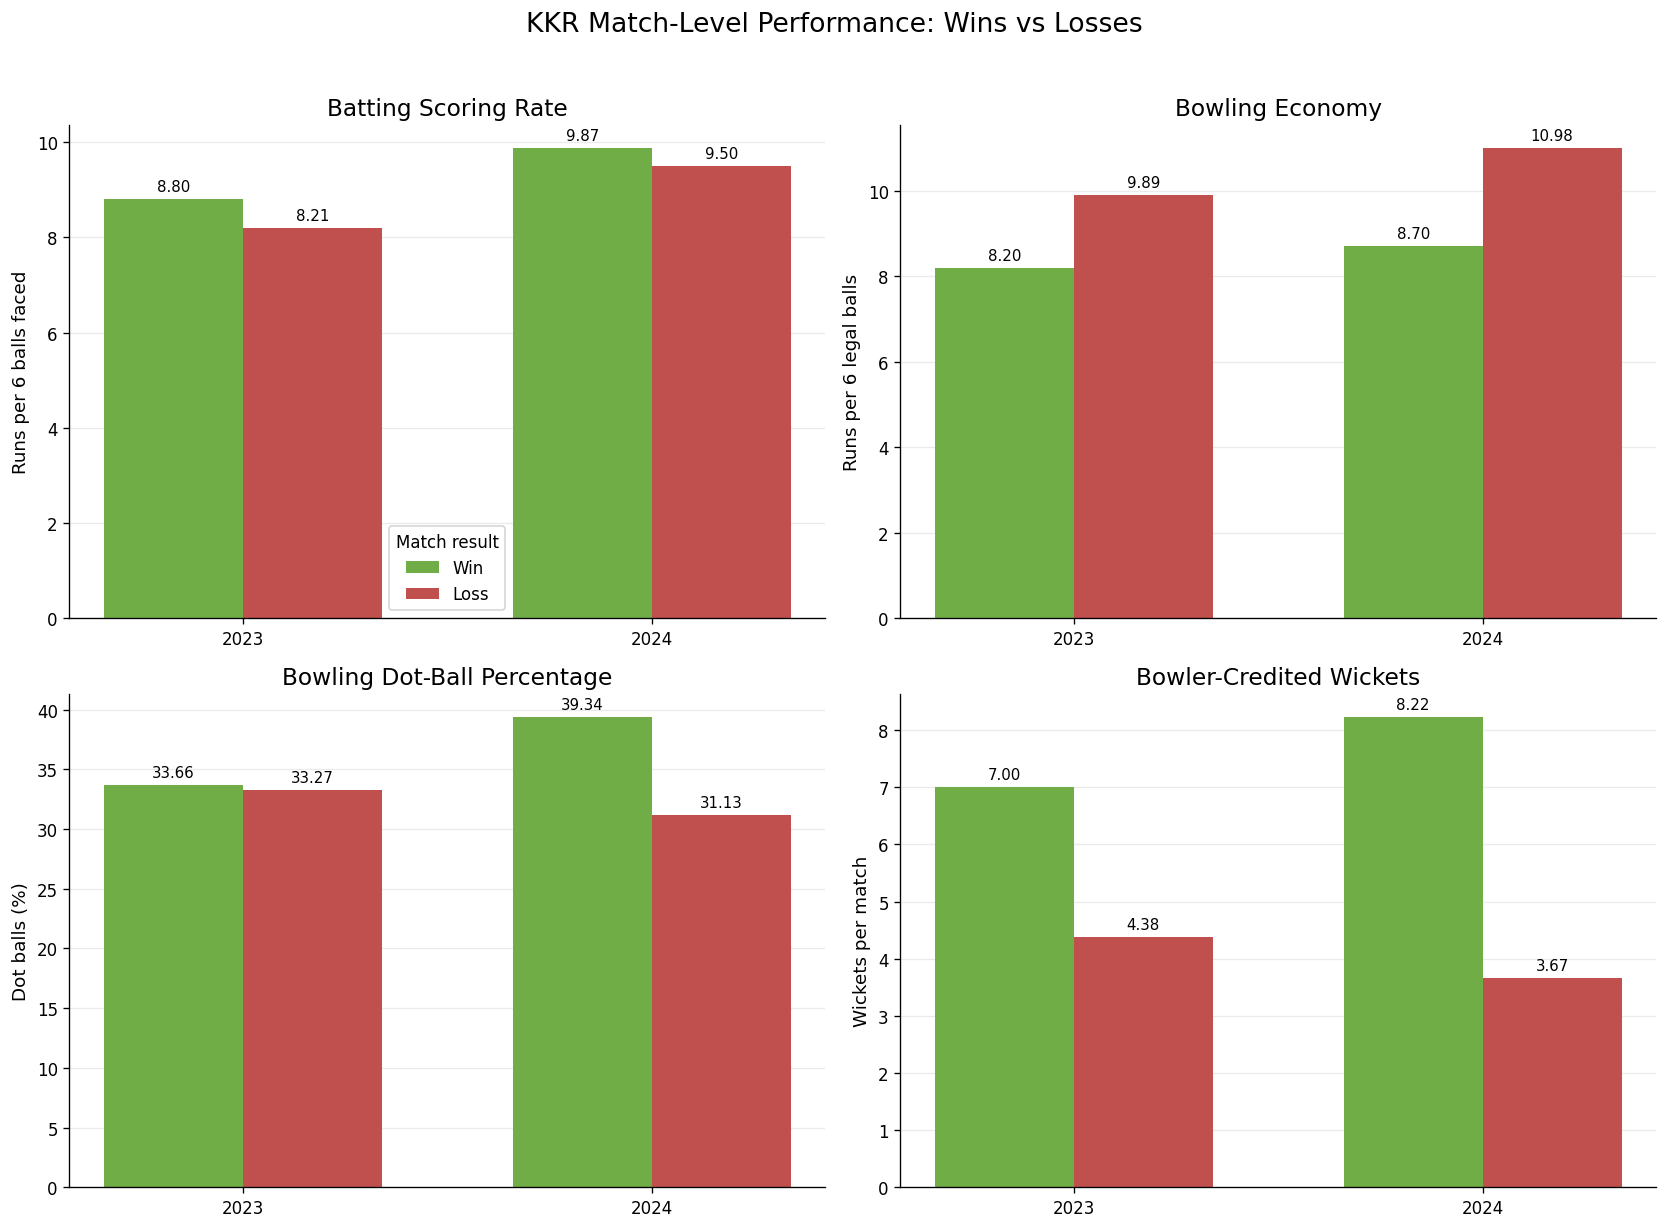

In [60]:
# Compare KKR wins and losses across four match-level metrics

metrics = [
    ("batting_runs_per_over", "Batting Scoring Rate", "Runs per 6 balls faced"),
    ("bowling_economy", "Bowling Economy", "Runs per 6 legal balls"),
    ("bowling_dot_pct", "Bowling Dot-Ball Percentage", "Dot balls (%)"),
    ("bowling_wickets", "Bowler-Credited Wickets", "Wickets per match"),
]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

results = ["Win", "Loss"]
result_colors = {
    "Win": "#70AD47",
    "Loss": "#C0504D",
}

for ax, (metric, title, ylabel) in zip(axes, metrics):
    plot_data = (
        kkr_league_matches.loc[
            kkr_league_matches["team_result"].isin(results)
        ]
        .groupby(["year", "team_result"])[metric]
        .mean()
        .unstack()
        .reindex(index=[2023, 2024], columns=results)
    )

    x = np.arange(len(plot_data.index))
    width = 0.34

    for i, result in enumerate(results):
        values = plot_data[result]

        bars = ax.bar(
            x + (i - 0.5) * width,
            values,
            width,
            label=result,
            color=result_colors[result],
        )

        ax.bar_label(bars, fmt="%.2f", padding=3, fontsize=9)

    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.set_xticks(x)
    ax.set_xticklabels(plot_data.index.astype(str))
    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)

axes[0].legend(title="Match result")

fig.suptitle(
    "KKR Match-Level Performance: Wins vs Losses",
    fontsize=16,
    y=1.02,
)

plt.tight_layout()
plt.show()

## 5. Player Scouting: Death Overs Batting Profiles

This section explores potential batting profiles using historical performance across the Death Overs (overs 16–20).

We focus on strike rate and boundary-ball percentage, while applying a minimum-ball threshold to reduce the influence of very small samples.

These metrics support exploratory player comparisons. They do not, by themselves, establish recruitment suitability or predict future performance. Team requirements, role, opposition, workload, and availability would need separate consideration.

In [61]:
# Identify eligible external Death Overs batting profiles

MIN_DEATH_BALLS = 30

death_batting = player_season_phase_batting.loc[
    player_season_phase_batting["match_phase"].eq("Death")
    & player_season_phase_batting["balls_faced"].ge(MIN_DEATH_BALLS)
].copy()

# Identify players who represented KKR in each season
kkr_player_season_ids = (
    df_features.loc[
        df_features["team_bat"].eq("Kolkata Knight Riders"),
        ["year", "p_bat"],
    ]
    .drop_duplicates()
)

# Exclude KKR player-seasons using player IDs and season
kkr_player_season_ids = kkr_player_season_ids.rename(
    columns={"p_bat": "p_bat"}
)

death_batting_external = death_batting.merge(
    kkr_player_season_ids.assign(is_kkr=True),
    on=["year", "p_bat"],
    how="left",
    validate="many_to_one",
)

death_batting_external = death_batting_external.loc[
    death_batting_external["is_kkr"].isna()
].drop(columns="is_kkr")

death_batting_external = death_batting_external.sort_values(
    ["strike_rate", "boundary_ball_pct"],
    ascending=False,
)

print(
    "Eligible external Death Overs player-season records:",
    len(death_batting_external),
)

display(
    death_batting_external[
        [
            "year",
            "batter_name",
            "runs",
            "balls_faced",
            "strike_rate",
            "boundary_ball_pct",
            "dot_ball_pct",
        ]
    ].head(15).round(2)
)

Eligible external Death Overs player-season records: 88


,year,batter_name,runs,balls_faced,strike_rate,boundary_ball_pct,dot_ball_pct
41,2024,Tristan Stubbs,252,96,262.50,39.58,11.46
35,2023,Vijay Shankar,122,47,259.57,38.30,17.02
24,2023,Liam Livingstone,103,41,251.22,39.02,34.15
69,2024,Rishabh Pant,133,59,225.42,33.90,23.73
21,2024,Shashank Singh,135,61,221.31,32.79,19.67
1,2024,MS Dhoni,161,73,220.55,36.99,30.14
19,2023,Glenn Maxwell,68,31,219.35,35.48,35.48
61,2023,Rashid Khan,102,47,217.02,36.17,40.43
4,2024,Dinesh Karthik,249,116,214.66,33.62,27.59
81,2023,Sai Sudharsan,88,41,214.63,34.15,14.63


In [62]:
# Minimum workload for Powerplay batting scouting
MIN_PP_BALLS = 60

# Filter Powerplay batting records with sufficient workload
pp_batting = player_season_phase_batting.loc[
    player_season_phase_batting["match_phase"].eq("Powerplay")
    & player_season_phase_batting["balls_faced"].ge(MIN_PP_BALLS)
].copy()

# Identify KKR batters by season using delivery-level data
kkr_batter_season_ids = (
    df_features.loc[
        df_features["team_bat"].eq("Kolkata Knight Riders"),
        ["year", "p_bat"]
    ]
    .drop_duplicates()
    .assign(is_kkr=True)
)

# Mark KKR players while preserving the player-season grain
pp_batting = pp_batting.merge(
    kkr_batter_season_ids,
    on=["year", "p_bat"],
    how="left",
    validate="many_to_one"
)

pp_batting["is_kkr"] = pp_batting["is_kkr"].fillna(False)

# Display KKR and external player profiles separately
pp_batting = pp_batting.sort_values(
    ["is_kkr", "strike_rate"],
    ascending=[False, False]
)

print(f"Eligible player-season records: {len(pp_batting)}")
print(f"KKR records: {pp_batting['is_kkr'].sum()}")
print(f"External records: {(~pp_batting['is_kkr']).sum()}")

display(
    pp_batting[
        [
            "year", "batter_name", "runs", "balls_faced",
            "strike_rate", "dot_ball_pct", "boundary_ball_pct",
            "is_kkr"
        ]
    ].head(20)
)

Eligible player-season records: 62
KKR records: 6
External records: 56


,year,batter_name,runs,balls_faced,strike_rate,dot_ball_pct,boundary_ball_pct,is_kkr
35,2024,Phil Salt,296,160,185.000000,40.625000,33.125000,True
8,2024,Sunil Narine,281,165,170.303030,46.060606,30.303030,True
16,2023,Jason Roy,177,121,146.280992,48.760331,27.272727,True
32,2023,Nitish Rana,94,71,132.394366,49.295775,21.126761,True
39,2023,Venkatesh Iyer,142,109,130.275229,50.458716,21.100917,True
42,2023,Rahmanullah Gurbaz,145,112,129.464286,53.571429,19.642857,True
60,2024,Jake Fraser-McGurk,266,106,250.943396,36.792453,49.056604,False
11,2023,Ajinkya Rahane,125,60,208.333333,23.333333,31.666667,False
30,2024,Travis Head,402,193,208.290155,33.160622,38.341969,False
50,2024,Abhishek Sharma,343,169,202.958580,34.911243,33.136095,False


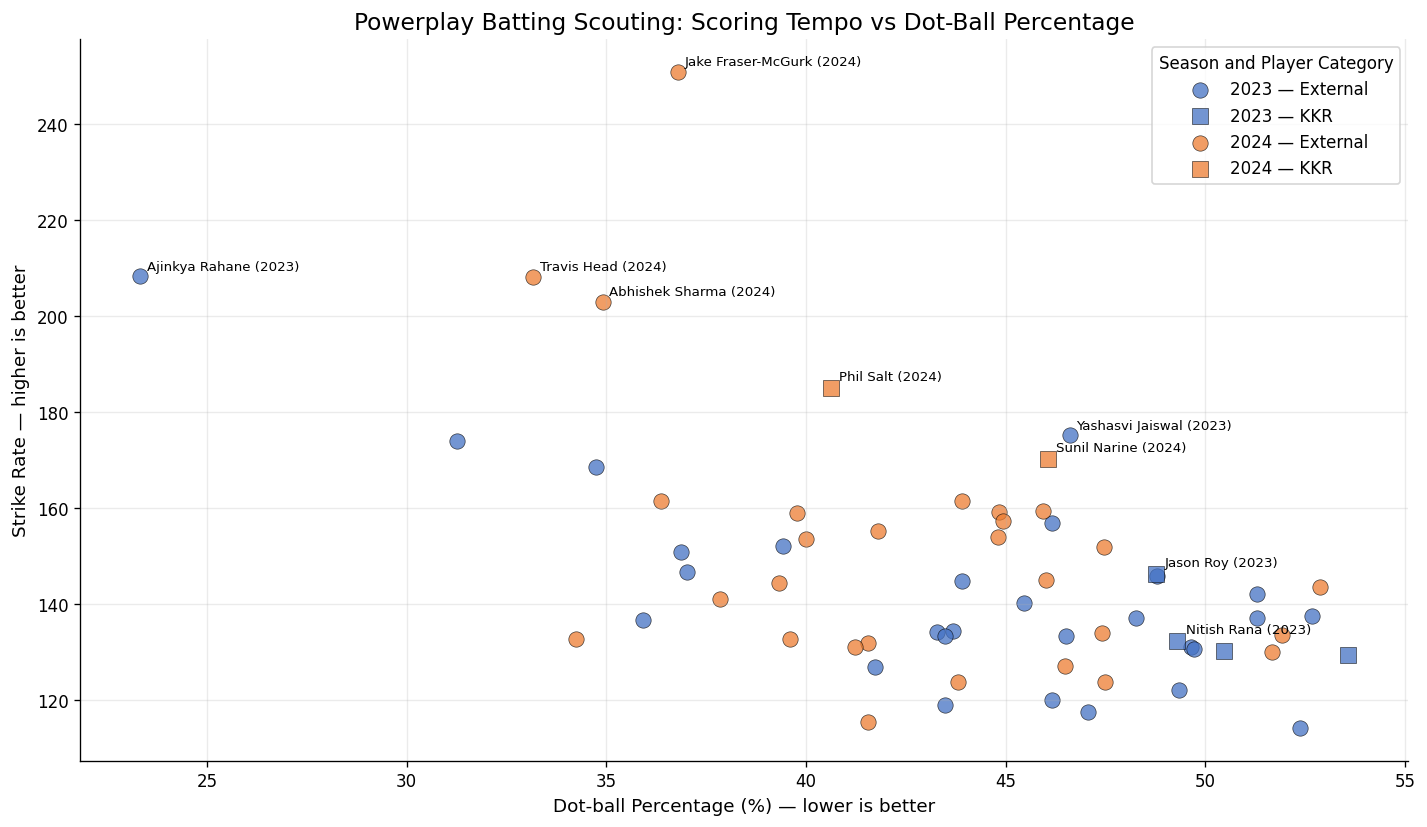

In [63]:
fig, ax = plt.subplots(figsize=(12, 7))

# Plot all players with consistent marker styling
for year in [2023, 2024]:
    for is_kkr in [False, True]:
        subset = pp_batting.loc[
            pp_batting["year"].eq(year)
            & pp_batting["is_kkr"].eq(is_kkr)
        ]

        ax.scatter(
            subset["dot_ball_pct"],
            subset["strike_rate"],
            color=SEASON_COLORS[year],
            marker=PLAYER_MARKERS[is_kkr],
            label=f"{year} — {'KKR' if is_kkr else 'External'}",
            s=85,
            alpha=0.75,
            edgecolors="black",
            linewidths=0.4
        )

# Label two KKR players per season, where available
kkr_labels = (
    pp_batting.loc[pp_batting["is_kkr"]]
    .sort_values(["year", "strike_rate"], ascending=[True, False])
    .groupby("year", group_keys=False)
    .head(2)
)

for _, row in kkr_labels.iterrows():
    ax.annotate(
        f"{row['batter_name']} ({int(row['year'])})",
        (row["dot_ball_pct"], row["strike_rate"]),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8
    )

# Label the five highest-strike-rate external players
external_labels = (
    pp_batting.loc[~pp_batting["is_kkr"]]
    .nlargest(5, "strike_rate")
)

for _, row in external_labels.iterrows():
    ax.annotate(
        f"{row['batter_name']} ({int(row['year'])})",
        (row["dot_ball_pct"], row["strike_rate"]),
        xytext=(4, 4),
        textcoords="offset points",
        fontsize=8
    )

ax.set_title("Powerplay Batting Scouting: Scoring Tempo vs Dot-Ball Percentage")
ax.set_xlabel("Dot-ball Percentage (%) — lower is better")
ax.set_ylabel("Strike Rate — higher is better")
ax.legend(title="Season and Player Category")
ax.grid(axis="both", alpha=0.25)

plt.tight_layout()
plt.show()

In [64]:
MIN_MIDDLE_BALLS = 60

middle_batting = player_season_phase_batting.loc[
    player_season_phase_batting["match_phase"].eq("Middle")
    & player_season_phase_batting["balls_faced"].ge(MIN_MIDDLE_BALLS)
].copy()

kkr_batter_season_ids = (
    df_features.loc[
        df_features["team_bat"].eq("Kolkata Knight Riders"),
        ["year", "p_bat"]
    ]
    .drop_duplicates()
    .assign(is_kkr=True)
)

middle_batting = middle_batting.merge(
    kkr_batter_season_ids,
    on=["year", "p_bat"],
    how="left",
    validate="many_to_one"
)

middle_batting["is_kkr"] = middle_batting["is_kkr"].fillna(False)

middle_batting = middle_batting.sort_values(
    ["is_kkr", "strike_rate"],
    ascending=[False, False]
)

print(f"Eligible player-season records: {len(middle_batting)}")
print(f"KKR records: {middle_batting['is_kkr'].sum()}")
print(f"External records: {(~middle_batting['is_kkr']).sum()}")

display(
    middle_batting[
        [
            "year", "batter_name", "runs", "balls_faced",
            "strike_rate", "dot_ball_pct", "boundary_ball_pct",
            "is_kkr"
        ]
    ].head(20)
)

Eligible player-season records: 100
KKR records: 9
External records: 91


,year,batter_name,runs,balls_faced,strike_rate,dot_ball_pct,boundary_ball_pct,is_kkr
8,2024,Sunil Narine,177,93,190.322581,31.182796,29.032258,True
60,2024,Phil Salt,134,76,176.315789,27.631579,26.315789,True
18,2023,Jason Roy,108,67,161.194030,25.373134,22.388060,True
70,2023,Venkatesh Iyer,234,146,160.273973,18.493151,17.808219,True
71,2024,Venkatesh Iyer,199,140,142.142857,34.285714,17.142857,True
57,2024,Shreyas Iyer,220,157,140.127389,28.662420,18.471338,True
54,2023,Nitish Rana,269,193,139.378238,33.678756,19.170984,True
12,2023,Andre Russell,93,74,125.675676,41.891892,14.864865,True
68,2023,Rinku Singh,176,156,112.820513,31.410256,10.256410,True
78,2024,Abhishek Sharma,141,68,207.352941,30.882353,32.352941,False


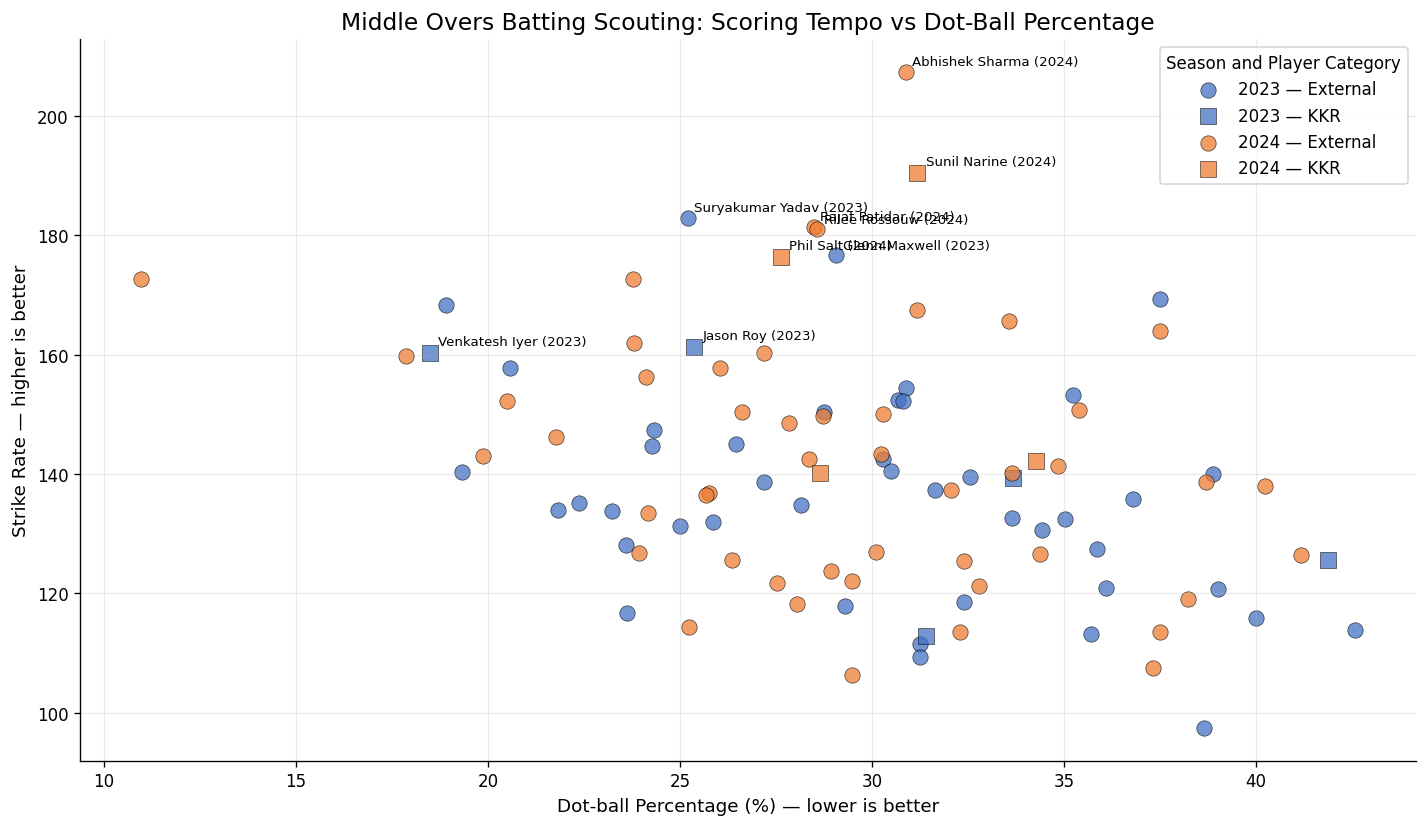

In [65]:
fig, ax = plt.subplots(figsize=(12, 7))

# Plot all players with consistent marker styling
for year in [2023, 2024]:
    for is_kkr in [False, True]:
        subset = middle_batting.loc[
            middle_batting["year"].eq(year)
            & middle_batting["is_kkr"].eq(is_kkr)
        ]

        ax.scatter(
            subset["dot_ball_pct"],
            subset["strike_rate"],
            color=SEASON_COLORS[year],
            marker=PLAYER_MARKERS[is_kkr],
            label=f"{year} — {'KKR' if is_kkr else 'External'}",
            s=85,
            alpha=0.75,
            edgecolors="black",
            linewidths=0.4
        )

# Label two KKR players per season, where available
kkr_labels = (
    middle_batting.loc[middle_batting["is_kkr"]]
    .sort_values(["year", "strike_rate"], ascending=[True, False])
    .groupby("year", group_keys=False)
    .head(2)
)

for _, row in kkr_labels.iterrows():
    ax.annotate(
        f"{row['batter_name']} ({int(row['year'])})",
        (row["dot_ball_pct"], row["strike_rate"]),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8
    )

# Label the five highest-strike-rate external players
external_labels = (
    middle_batting.loc[~middle_batting["is_kkr"]]
    .nlargest(5, "strike_rate")
)

for _, row in external_labels.iterrows():
    ax.annotate(
        f"{row['batter_name']} ({int(row['year'])})",
        (row["dot_ball_pct"], row["strike_rate"]),
        xytext=(4, 4),
        textcoords="offset points",
        fontsize=8
    )

ax.set_title("Middle Overs Batting Scouting: Scoring Tempo vs Dot-Ball Percentage")
ax.set_xlabel("Dot-ball Percentage (%) — lower is better")
ax.set_ylabel("Strike Rate — higher is better")
ax.legend(title="Season and Player Category")
ax.grid(axis="both", alpha=0.25)

plt.tight_layout()
plt.show()

In [66]:
MIN_DEATH_BALLS = 30

death_batting = player_season_phase_batting.loc[
    player_season_phase_batting["match_phase"].eq("Death")
    & player_season_phase_batting["balls_faced"].ge(MIN_DEATH_BALLS)
].copy()

kkr_batter_season_ids = (
    df_features.loc[
        df_features["team_bat"].eq("Kolkata Knight Riders"),
        ["year", "p_bat"]
    ]
    .drop_duplicates()
    .assign(is_kkr=True)
)

death_batting = death_batting.merge(
    kkr_batter_season_ids,
    on=["year", "p_bat"],
    how="left",
    validate="many_to_one"
)

death_batting["is_kkr"] = death_batting["is_kkr"].fillna(False)

death_batting = death_batting.sort_values(
    ["is_kkr", "strike_rate"],
    ascending=[False, False]
)

print(f"Eligible player-season records: {len(death_batting)}")
print(f"KKR records: {death_batting['is_kkr'].sum()}")
print(f"External records: {(~death_batting['is_kkr']).sum()}")

display(
    death_batting[
        [
            "year", "batter_name", "runs", "balls_faced",
            "strike_rate", "dot_ball_pct", "boundary_ball_pct",
            "is_kkr"
        ]
    ].head(20)
)

Eligible player-season records: 95
KKR records: 7
External records: 88


,year,batter_name,runs,balls_faced,strike_rate,dot_ball_pct,boundary_ball_pct,is_kkr
13,2024,Andre Russell,135,64,210.937500,29.687500,34.375000,True
46,2024,Shreyas Iyer,113,56,201.785714,19.642857,28.571429,True
58,2023,Rinku Singh,280,150,186.666667,32.000000,27.333333,True
59,2024,Rinku Singh,86,48,179.166667,27.083333,25.000000,True
12,2023,Andre Russell,134,82,163.414634,43.902439,24.390244,True
64,2024,Venkatesh Iyer,60,43,139.534884,44.186047,18.604651,True
34,2023,Shardul Thakur,52,39,133.333333,35.897436,20.512821,True
41,2024,Tristan Stubbs,252,96,262.500000,11.458333,39.583333,False
35,2023,Vijay Shankar,122,47,259.574468,17.021277,38.297872,False
24,2023,Liam Livingstone,103,41,251.219512,34.146341,39.024390,False


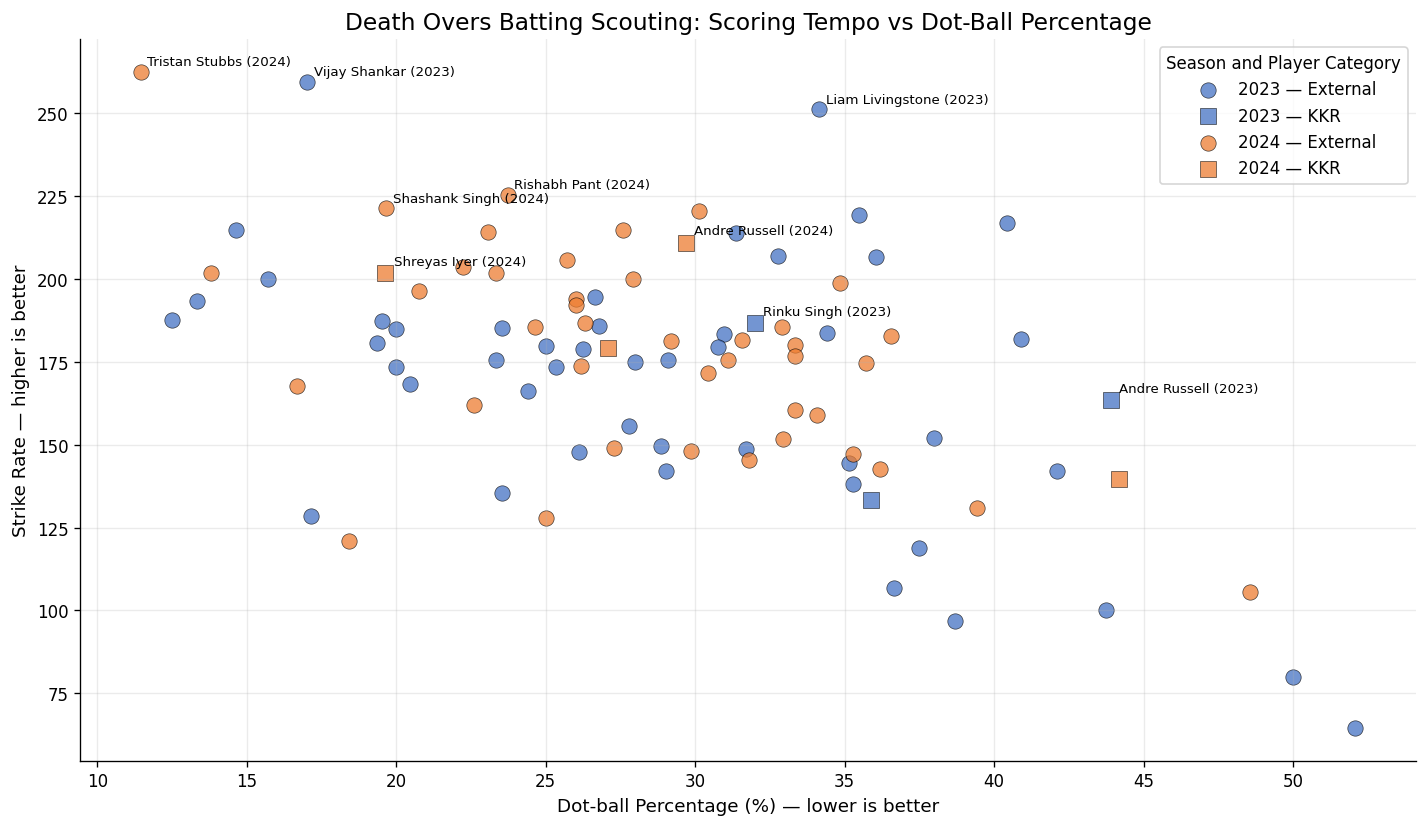

In [67]:
fig, ax = plt.subplots(figsize=(12, 7))

# Consistent marker size and styling for all players
for year in [2023, 2024]:
    for is_kkr in [False, True]:
        subset = death_batting.loc[
            death_batting["year"].eq(year)
            & death_batting["is_kkr"].eq(is_kkr)
        ]

        ax.scatter(
            subset["dot_ball_pct"],
            subset["strike_rate"],
            color=SEASON_COLORS[year],
            marker=PLAYER_MARKERS[is_kkr],
            label=f"{year} — {'KKR' if is_kkr else 'External'}",
            s=85,
            alpha=0.75,
            edgecolors="black",
            linewidths=0.4
        )

# Label two KKR players per season, where available
kkr_labels = (
    death_batting.loc[death_batting["is_kkr"]]
    .sort_values(["year", "strike_rate"], ascending=[True, False])
    .groupby("year", group_keys=False)
    .head(2)
)

for _, row in kkr_labels.iterrows():
    ax.annotate(
        f"{row['batter_name']} ({int(row['year'])})",
        (row["dot_ball_pct"], row["strike_rate"]),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8
    )

# Label the five highest-strike-rate external players
external_labels = (
    death_batting.loc[~death_batting["is_kkr"]]
    .nlargest(5, "strike_rate")
)

for _, row in external_labels.iterrows():
    ax.annotate(
        f"{row['batter_name']} ({int(row['year'])})",
        (row["dot_ball_pct"], row["strike_rate"]),
        xytext=(4, 4),
        textcoords="offset points",
        fontsize=8
    )

ax.set_title("Death Overs Batting Scouting: Scoring Tempo vs Dot-Ball Percentage")
ax.set_xlabel("Dot-ball Percentage (%) — lower is better")
ax.set_ylabel("Strike Rate — higher is better")
ax.legend(title="Season and Player Category")
ax.grid(axis="both", alpha=0.25)

plt.tight_layout()
plt.show()

In [68]:
# Minimum legal-ball thresholds
MIN_PP_BOWLING_BALLS = 60
MIN_MIDDLE_BOWLING_BALLS = 60
MIN_DEATH_BOWLING_BALLS = 30

# Identify KKR bowlers by season
kkr_bowler_season_ids = (
    df_features.loc[
        df_features["team_bowl"].eq("Kolkata Knight Riders"),
        ["year", "p_bowl"]
    ]
    .drop_duplicates()
    .assign(is_kkr=True)
)


def prepare_bowling_scouting(phase, min_balls):
    """Prepare comparable KKR and external bowling profiles for one phase."""

    scouting = player_season_phase_bowling.loc[
        player_season_phase_bowling["match_phase"].eq(phase)
        & player_season_phase_bowling["legal_balls"].ge(min_balls)
    ].copy()

    scouting = scouting.merge(
        kkr_bowler_season_ids,
        on=["year", "p_bowl"],
        how="left",
        validate="many_to_one"
    )

    scouting["is_kkr"] = scouting["is_kkr"].fillna(False)

    # Wickets per 20 legal overs
    scouting["wickets_per_20_overs"] = (
        20 * scouting["wickets"] / scouting["overs_bowled"]
    )

    return scouting.sort_values(
        ["is_kkr", "wickets_per_20_overs"],
        ascending=[False, False]
    )


pp_bowling = prepare_bowling_scouting(
    "Powerplay", MIN_PP_BOWLING_BALLS
)

middle_bowling = prepare_bowling_scouting(
    "Middle", MIN_MIDDLE_BOWLING_BALLS
)

death_bowling = prepare_bowling_scouting(
    "Death", MIN_DEATH_BOWLING_BALLS
)

# Validate the candidate pools
for phase, scouting in [
    ("Powerplay", pp_bowling),
    ("Middle Overs", middle_bowling),
    ("Death Overs", death_bowling),
]:
    print(f"\n{phase}")
    print(f"Eligible player-season records: {len(scouting)}")
    print(f"KKR records: {scouting['is_kkr'].sum()}")
    print(f"External records: {(~scouting['is_kkr']).sum()}")


Powerplay
Eligible player-season records: 65
KKR records: 6
External records: 59

Middle Overs
Eligible player-season records: 87
KKR records: 7
External records: 80

Death Overs
Eligible player-season records: 89
KKR records: 10
External records: 79


In [69]:
def plot_bowling_scouting(scouting, phase):
    fig, ax = plt.subplots(figsize=(12, 7))

    for year in [2023, 2024]:
        for is_kkr in [False, True]:
            subset = scouting.loc[
                scouting["year"].eq(year)
                & scouting["is_kkr"].eq(is_kkr)
            ]

            ax.scatter(
                subset["economy_rate"],
                subset["wickets_per_20_overs"],
                color=SEASON_COLORS[year],
                marker=PLAYER_MARKERS[is_kkr],
                label=f"{year} — {'KKR' if is_kkr else 'External'}",
                s=85,
                alpha=0.75,
                edgecolors="black",
                linewidths=0.4
            )

    # Label two KKR bowlers per season, where available
    kkr_labels = (
        scouting.loc[scouting["is_kkr"]]
        .sort_values(
            ["year", "wickets_per_20_overs"],
            ascending=[True, False]
        )
        .groupby("year", group_keys=False)
        .head(2)
    )

    for _, row in kkr_labels.iterrows():
        ax.annotate(
            f"{row['bowler_name']} ({int(row['year'])})",
            (row["economy_rate"], row["wickets_per_20_overs"]),
            xytext=(5, 5),
            textcoords="offset points",
            fontsize=8
        )

    # Label five external bowlers with the highest wicket rates
    external_labels = (
        scouting.loc[~scouting["is_kkr"]]
        .nlargest(5, "wickets_per_20_overs")
    )

    for _, row in external_labels.iterrows():
        ax.annotate(
            f"{row['bowler_name']} ({int(row['year'])})",
            (row["economy_rate"], row["wickets_per_20_overs"]),
            xytext=(4, 4),
            textcoords="offset points",
            fontsize=8
        )

    ax.set_title(
        f"{phase} Bowling Scouting: Economy vs Wicket-Taking Rate"
    )
    ax.set_xlabel("Economy Rate (runs per over) — lower is better")
    ax.set_ylabel("Wickets per 20 Legal Overs — higher is better")
    ax.legend(title="Season and Player Category")
    ax.grid(axis="both", alpha=0.25)

    plt.tight_layout()
    plt.show()

    # Supporting table for interpretation
    display(
        scouting.sort_values(
            ["is_kkr", "wickets_per_20_overs"],
            ascending=[False, False]
        )[
            [
                "year",
                "bowler_name",
                "legal_balls",
                "wickets",
                "economy_rate",
                "bowling_dot_pct",
                "wickets_per_20_overs",
                "is_kkr"
            ]
        ].head(20)
    )

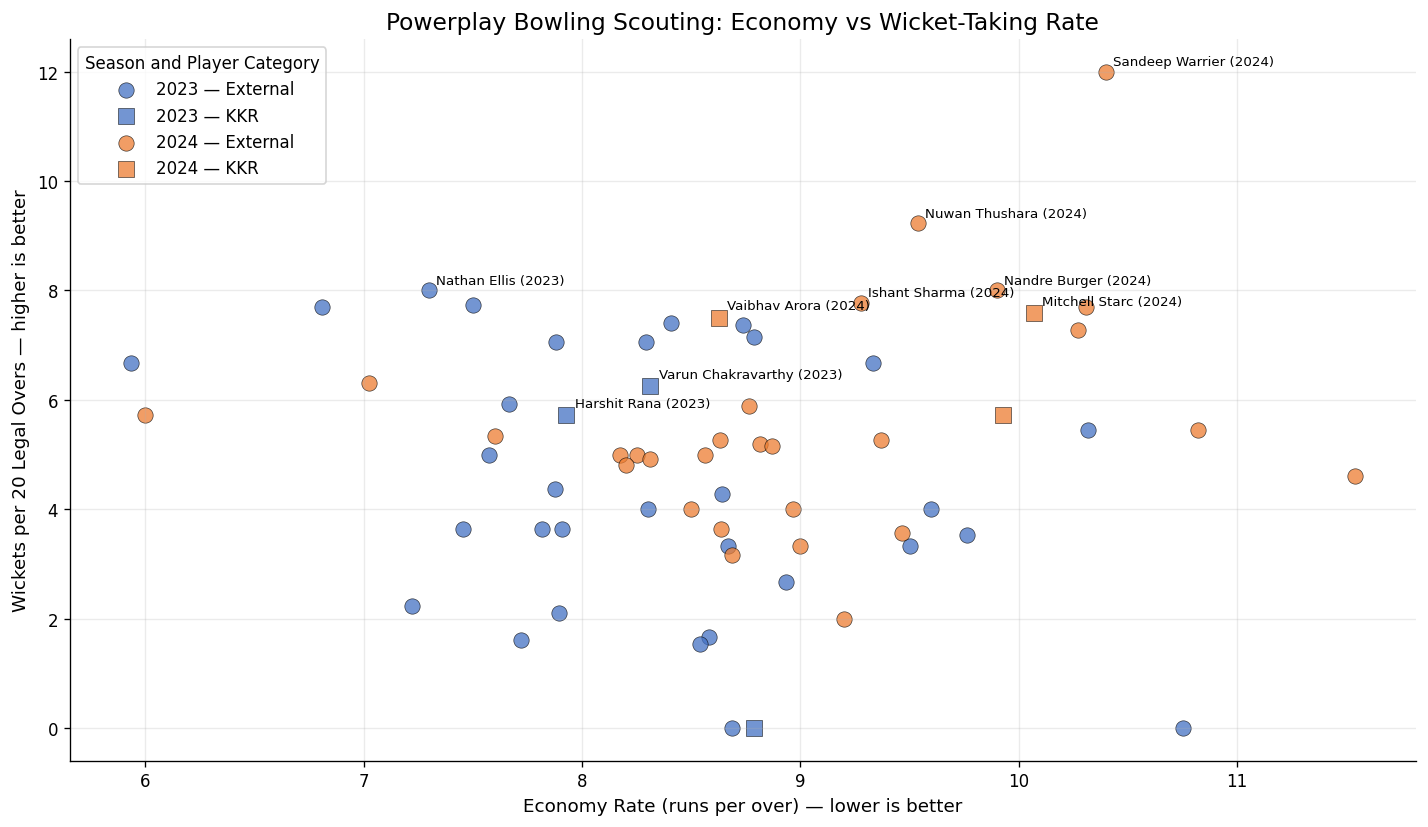

,year,bowler_name,legal_balls,wickets,economy_rate,bowling_dot_pct,wickets_per_20_overs,is_kkr
9,2024,Mitchell Starc,174,11,10.068966,41.954023,7.586207,True
62,2024,Vaibhav Arora,144,9,8.625000,43.750000,7.500000,True
55,2023,Varun Chakravarthy,96,5,8.312500,40.625000,6.250000,True
63,2023,Harshit Rana,84,4,7.928571,47.619048,5.714286,True
64,2024,Harshit Rana,84,4,9.928571,44.047619,5.714286,True
13,2023,Umesh Yadav,84,0,8.785714,42.857143,0.000000,True
27,2024,Sandeep Warrier,60,6,10.400000,46.666667,12.000000,False
52,2024,Nuwan Thushara,78,6,9.538462,41.025641,9.230769,False
44,2023,Nathan Ellis,60,4,7.300000,40.000000,8.000000,False
53,2024,Nandre Burger,60,4,9.900000,48.333333,8.000000,False


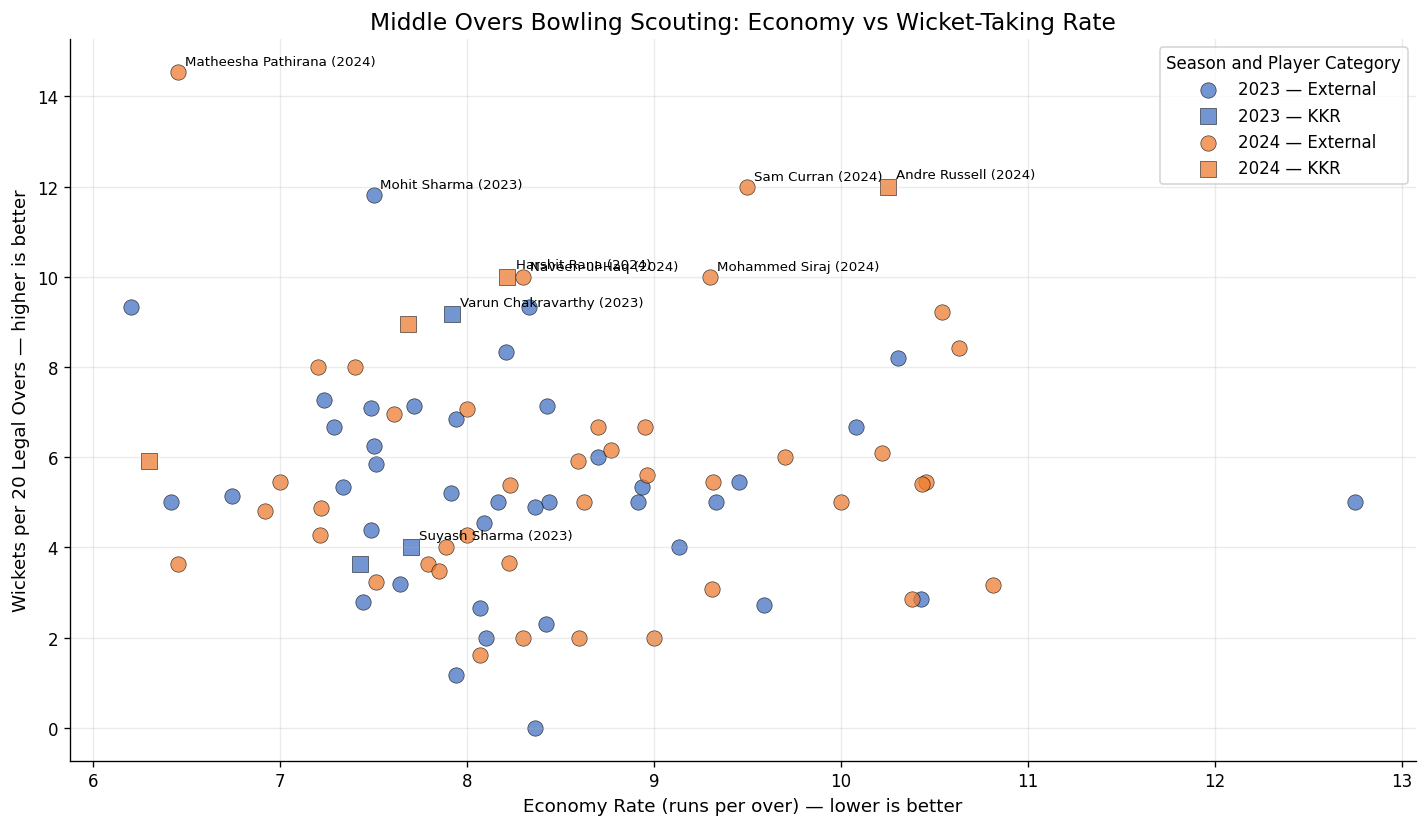

,year,bowler_name,legal_balls,wickets,economy_rate,bowling_dot_pct,wickets_per_20_overs,is_kkr
13,2024,Andre Russell,120,12,10.250000,30.833333,12.000000,True
85,2024,Harshit Rana,84,7,8.214286,33.333333,10.000000,True
66,2023,Varun Chakravarthy,144,11,7.916667,36.111111,9.166667,True
67,2024,Varun Chakravarthy,228,17,7.684211,39.912281,8.947368,True
9,2024,Sunil Narine,264,13,6.295455,35.606061,5.909091,True
86,2023,Suyash Sharma,180,6,7.700000,35.555556,4.000000,True
8,2023,Sunil Narine,198,6,7.424242,26.262626,3.636364,True
83,2024,Matheesha Pathirana,66,8,6.454545,45.454545,14.545455,False
40,2024,Sam Curran,60,6,9.500000,28.333333,12.000000,False
29,2023,Mohit Sharma,132,13,7.500000,33.333333,11.818182,False


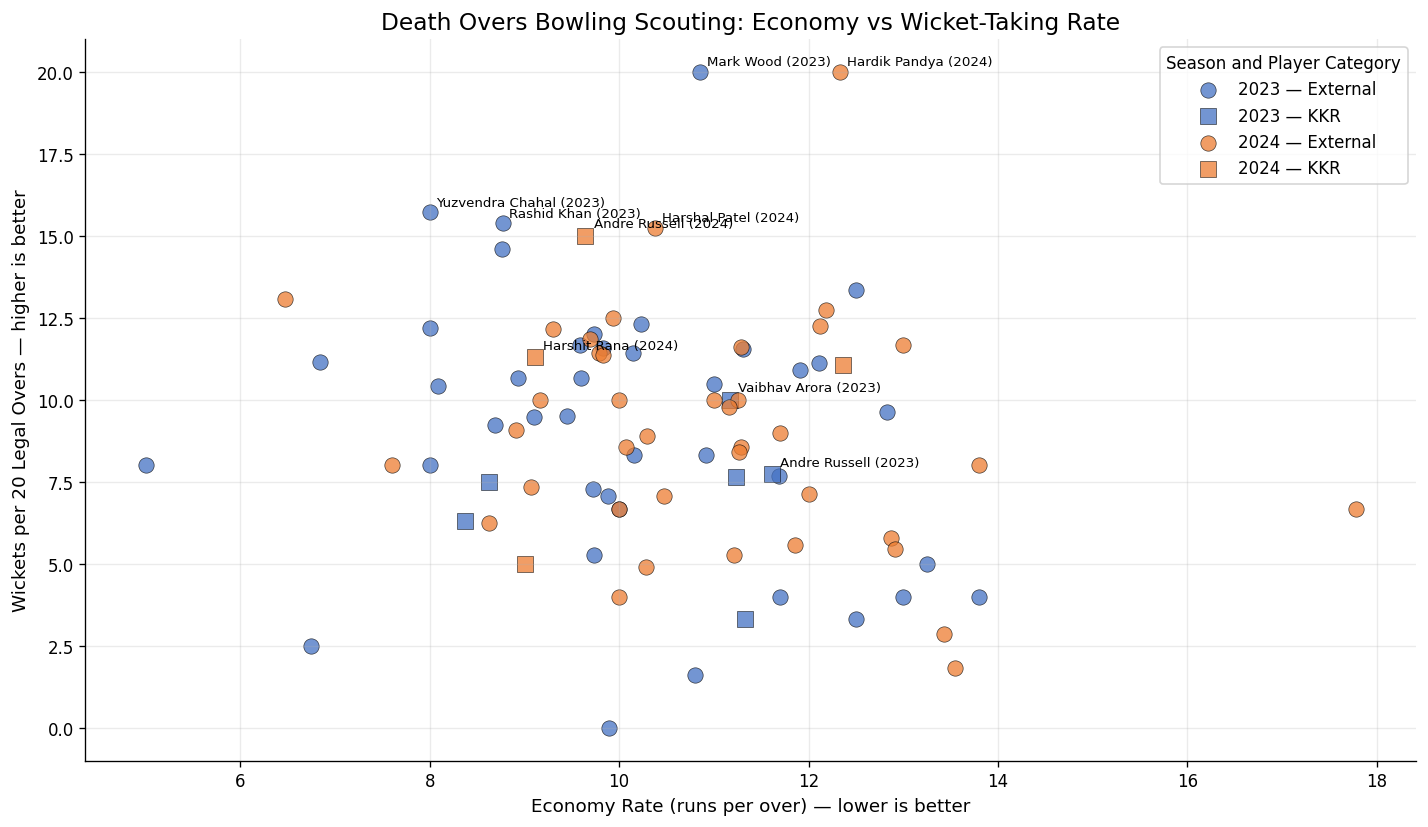

,year,bowler_name,legal_balls,wickets,economy_rate,bowling_dot_pct,wickets_per_20_overs,is_kkr
5,2024,Andre Russell,56,7,9.642857,41.071429,15.000000,True
87,2024,Harshit Rana,85,8,9.105882,32.941176,11.294118,True
9,2024,Mitchell Starc,65,6,12.369231,38.461538,11.076923,True
86,2023,Vaibhav Arora,36,3,11.166667,22.222222,10.000000,True
4,2023,Andre Russell,31,2,11.612903,25.806452,7.741935,True
23,2023,Shardul Thakur,47,3,11.234043,23.404255,7.659574,True
2,2023,Sunil Narine,48,3,8.625000,25.000000,7.500000,True
71,2023,Varun Chakravarthy,76,4,8.368421,31.578947,6.315789,True
72,2024,Varun Chakravarthy,48,2,9.000000,43.750000,5.000000,True
88,2023,Suyash Sharma,36,1,11.333333,25.000000,3.333333,True


In [71]:
plot_bowling_scouting(pp_bowling, "Powerplay")

plot_bowling_scouting(middle_bowling, "Middle Overs")

plot_bowling_scouting(death_bowling, "Death Overs")

## 12. Strategic Recommendations

### 12.1 Overall Performance Assessment

### 12.2 Batting Strategy by Phase

### 12.3 Bowling Strategy by Phase

### 12.4 Player Scouting Priorities

### 12.5 Tactical Match-up Implications

### 12.6 Limitations and Decision Risks

## 12. Strategic Recommendations

### 12.1 Overall Performance Assessment

KKR's represented-match win percentage increased from 42.86% in 2023 (6 wins from 14 matches) to 78.57% in 2024 (11 wins from 14 matches).

For a more comparable league-only assessment, KKR won 6 of 14 matches in 2023 and 9 of 12 represented league matches in 2024. The 2024 dataset also contains Qualifier 1 and the Final, while KKR's last two league matches are absent.

The results indicate a substantial improvement in KKR's observed performance, but the difference in match coverage must be considered when comparing seasons.

KKR's mean innings score increased from 175.86 in 2023 to 190.14 in 2024. However, the median declined from 180.5 to 177.5, while the standard deviation increased from 25.16 to 47.01. Exceptional scores contributed to the higher 2024 mean.

**Recommendation:** Evaluate the improvement using several indicators together—results, phase-wise scoring, bowling effectiveness and performance consistency—rather than relying on win percentage or average score alone.

### 12.2 Batting Strategy by Phase

#### Powerplay

KKR's scoring rate increased from 7.70 runs per over in 2023 to 10.05 in 2024.

Phil Salt and Sunil Narine scored 577 of KKR's 849 Powerplay runs in the represented 2024 matches, making their contribution central to the observed improvement.

**Recommendation:** Preserve the aggressive opening approach while maintaining sufficient flexibility for different match situations. Evaluate potential opening-batting additions against the contributions and roles of the existing options rather than assuming that another aggressive opener is automatically required.

#### Middle Overs

KKR's scoring rate increased from 8.41 to 9.22 runs per over.

The improvement was smaller than in the Powerplay and Death Overs, suggesting that the middle phase is worth examining for further opportunities to maintain scoring pressure.

**Recommendation:** Prioritise batters who can rotate strike, limit unproductive deliveries and accelerate against suitable bowling match-ups. Assess these attributes together instead of selecting players on strike rate alone.

#### Death Overs

KKR's scoring rate increased from 9.57 to 11.30 runs per over.

However, Death Overs coverage differs between seasons: 2023 contains 14 represented matches, while 2024 contains 12. Two successful 2024 chases ended before the Death Overs, so the phase-level comparison does not cover identical match samples.

**Recommendation:** Preserve the demonstrated finishing potential while evaluating batters using strike rate, dot-ball percentage, boundary-ball percentage and balls faced together. A high strike rate based on a small sample should not automatically outweigh a strong performance sustained over a larger workload.

### 12.3 Bowling Strategy by Phase

#### Powerplay Bowling

Powerplay economy increased slightly from 9.60 to 9.73 runs per over. At the same time, dot-ball percentage increased from 39.29% to 41.87%, and bowler-credited wickets increased from 20 to 27.

Wides increased from 24 to 37.

**Recommendation:** Retain the wicket-taking aspects of the Powerplay approach while investigating the increase in wides. Bowling discipline should be evaluated alongside wickets and economy, because additional extras can offset otherwise effective deliveries.

#### Middle-Overs Bowling

Middle-Overs economy remained approximately stable, moving from 8.13 to 8.11 runs per over. Dot-ball percentage increased from 33.15% to 35.05%, while bowler-credited wickets increased from 36 to 49.

**Recommendation:** Preserve the combination of scoring control and wicket-taking. When assessing bowlers, consider economy, dot-ball percentage, wicket output and workload together. Do not interpret the aggregate improvement as proof that every individual bowler improved.

#### Death-Overs Bowling

Death-Overs economy improved from 10.59 to 9.82 runs per over. Dot-ball percentage increased from 24.93% to 38.29%, while bowler-credited wickets increased from 21 to 28.

Harshit Rana and Andre Russell combined for 15 Death-Overs wickets in 2024, compared with two in 2023. Their combined legal-ball workload also increased substantially, from 37 to 141 balls.

**Recommendation:** Preserve the effective Death-Overs combination while monitoring workload and role allocation. The increased wicket contribution is encouraging, but the higher workload means it should not be attributed entirely to an improvement in individual effectiveness.

### 12.4 Player Scouting Priorities

The scouting analysis compares player-season profiles across the Powerplay, Middle Overs and Death Overs. It considers scoring tempo, dot-ball frequency, boundary frequency, economy, wicket-taking output and workload.

The Death-Overs batting analysis identified Tristan Stubbs as a notable external profile in the available dataset: 252 runs from 96 balls, a strike rate of 262.50, a boundary-ball percentage of 39.58% and a dot-ball percentage of 11.46%.

The bowling analysis also identified promising phase-specific historical profiles, including Jasprit Bumrah in the Death Overs and Mohammed Shami in the Powerplay.

These are statistical observations, not definitive recruitment recommendations.

**Recommendation:** Use the phase-specific comparisons to create a shortlist for further evaluation. Before making a recruitment decision, assess role suitability, availability, cost, workload, consistency, opposition quality and the existing squad composition. These factors are not fully established by the dataset.

### 12.5 Tactical Match-up Implications

The individual batter-versus-bowler analysis produced limited samples. Only 17 of 746 player match-up combinations met the exploratory threshold of at least 12 balls faced and two matches, and none reached 24 balls.

Opponent-phase aggregates provided broader descriptive comparisons, but several combinations still represented only one or two matches.

**Recommendation:** Use opponent-phase patterns to formulate tactical hypotheses rather than definitive match-up instructions. Avoid making strong claims about individual batter-bowler advantages when the observed sample is small. Validate promising hypotheses using additional seasons or more extensive ball-by-ball evidence.

### 12.6 Limitations and Decision Risks

The analysis has several limitations that affect the strength of its conclusions:

1. **Unequal match coverage:** The 2024 dataset contains 12 represented league matches and two playoffs, while KKR's final two league matches are absent. League-only comparisons must be distinguished from comparisons using all represented matches.

2. **Incomplete match:** One 2023 match has only one represented innings and one represented batting team. It is excluded from complete-match comparisons.

3. **Bowling-runs inconsistencies:** Fourteen delivery records contain discrepancies between the source `bowlruns` values and the candidate reconstruction from batting runs, wides and no-balls. Source values have been retained pending resolution.

4. **Metric definitions:** Batting balls faced, legal deliveries, batter dismissals and bowler-credited wickets are distinct concepts. The analysis uses explicitly defined metrics rather than treating them as interchangeable.

5. **Small player samples:** Players with limited phase-specific workloads can exhibit extreme rates. Minimum-ball thresholds reduce, but do not eliminate, this problem.

6. **Limited seasons:** Two seasons are insufficient to establish long-term player consistency or guarantee future performance.

7. **Clustering limitations:** The player-performance clusters are exploratory descriptions of historical profiles, not predictive rankings. Their modest silhouette scores indicate limited separation between groups.

8. **Descriptive rather than causal analysis:** The observed relationships between phase-level metrics and match outcomes do not establish that a particular metric independently caused a win.

**Final decision principle:** Treat the analysis as a structured decision-support framework. Prioritise findings supported by consistent metrics and adequate samples, investigate data-quality issues before high-stakes decisions, and validate player or tactical recommendations with additional evidence.